<a href="https://colab.research.google.com/github/SattikBhaumik/NS125-Research-Methods/blob/main/NS125_Data_Driven_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Load data

In [27]:
library(tidyverse)
library(readxl)

##Metadata

In [28]:
# all variable description
metadata <- read.csv("/content/howe-2016-metadata.csv")
metadata

YCOM.VARIABLE.NAME,VARIABLE.DESCRIPTION
<chr>,<chr>
Statecode,Geographic abbreviation
Statename,Geographic name
TotalPop,Total population
CO2limits,Estimated percentage who somewhat/strongly support setting strict limits on existing coal-fire power plants
CO2limitsOppose,Estimated percentage who somewhat/strongly oppose setting strict limits on existing coal-fire power plants
regulate,Estimated percentage who somewhat/strongly support regulating CO2 as a pollutant
regulateOppose,Estimated percentage who somewhat/strongly oppose regulating CO2 as a pollutant
supportRPS,Estimated percentage who somewhat/strongly support requiring utilities to produce 20% electricity from renewable sources
supportRPSOppose,Estimated percentage who somewhat/strongly oppose requiring utilities to produce 20% electricity from renewable sources


##Main Data

In [29]:
# main data description
climate <- read.csv("/content/howe-2016-data.csv", header = TRUE)
head(climate)

,GeoType,GEOID,GeoName,TotalPop,discuss,discussOppose,CO2limits,CO2limitsOppose,trustclimsciSST,trustclimsciSSTOppose,⋯,harmUS,harmUSOppose,devharm,devharmOppose,futuregen,futuregenOppose,harmplants,harmplantsOppose,timing,timingOppose
,<chr>,<int>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,National,9999,US,209056129,33.495,31.081,69.376,29.386,71.199,26.163,⋯,57.918,32.747,62.892,25.457,69.848,19.203,69.344,20.506,50.968,48.635
2,State,1,Alabama,3217902,27.468,38.892,63.122,35.589,66.416,30.717,⋯,52.079,35.565,56.025,28.731,61.881,23.292,61.369,24.528,46.644,52.978
3,State,2,Alaska,460319,36.632,28.074,68.231,31.123,65.712,29.466,⋯,55.117,37.327,61.542,28.235,66.820,22.328,69.005,23.129,48.295,51.022
4,State,4,Arizona,4284776,36.724,28.882,66.001,32.625,70.357,28.190,⋯,57.669,34.217,61.654,27.729,67.368,22.051,66.647,23.685,50.683,49.168
5,State,5,Arkansas,1949963,28.832,37.666,63.744,35.166,65.852,31.749,⋯,52.120,36.455,57.397,29.640,63.825,24.254,63.853,24.197,46.276,53.327
6,State,6,California,24865866,39.309,25.920,73.740,24.959,72.822,23.120,⋯,64.548,27.195,69.022,20.391,75.097,14.919,74.674,16.127,56.197,43.306


##Exploratory Data Analysis

In [30]:
# all types of regions
# National, State, County, cd113 (Congresstional Districts), CBSA
unique(climate$GeoType)
table(climate$GeoType)

[1] "National" "State"    "County"   "cd113"    "CBSA"


    CBSA    cd113   County National    State 
     916      435     3142        1       51 

In [31]:
# datatypes and total number of observations
str(climate)

'data.frame':	4545 obs. of  38 variables:
 $ GeoType              : chr  "National" "State" "State" "State" ...
 $ GEOID                : int  9999 1 2 4 5 6 8 9 10 11 ...
 $ GeoName              : chr  "US" "Alabama" "Alaska" "Arizona" ...
 $ TotalPop             : int  209056129 3217902 460319 4284776 1949963 24865866 3453403 2455577 620886 442721 ...
 $ discuss              : num  33.5 27.5 36.6 36.7 28.8 ...
 $ discussOppose        : num  31.1 38.9 28.1 28.9 37.7 ...
 $ CO2limits            : num  69.4 63.1 68.2 66 63.7 ...
 $ CO2limitsOppose      : num  29.4 35.6 31.1 32.6 35.2 ...
 $ trustclimsciSST      : num  71.2 66.4 65.7 70.4 65.9 ...
 $ trustclimsciSSTOppose: num  26.2 30.7 29.5 28.2 31.7 ...
 $ regulate             : num  74.8 70 73.1 72.8 70 ...
 $ regulateOppose       : num  24 28.7 25.8 26.6 29.1 ...
 $ supportRPS           : num  66 60.3 62.5 64.9 60.6 ...
 $ supportRPSOppose     : num  32.7 39.1 35.8 34.1 38.1 ...
 $ fundrenewables       : num  82.2 78.6 82.7 81.2 78 

In [32]:
# summary statistics for all variables
summary(climate)

      GeoType         GEOID            GeoName        TotalPop        
 Length   :4545   Min.   :    1   Length   :4545   Min.   :       67  
 N.unique :   5   1st Qu.:14500   N.unique :4545   1st Qu.:    11273  
 N.blank  :   0   Median :27149   N.blank  :   0   Median :    28756  
 Min.nchar:   4   Mean   :27277   Min.nchar:   2   Mean   :   494973  
 Max.nchar:   8   3rd Qu.:40620   Max.nchar:  64   3rd Qu.:   122245  
                  Max.   :56045                    Max.   :338629800  
                                                                      
    discuss      discussOppose     CO2limits     CO2limitsOppose
 Min.   :21.80   Min.   :17.19   Min.   :34.99   Min.   :13.74  
 1st Qu.:27.57   1st Qu.:30.26   1st Qu.:59.16   1st Qu.:30.07  
 Median :29.67   Median :33.33   Median :63.67   Median :35.00  
 Mean   :30.61   Mean   :33.41   Mean   :63.88   Mean   :34.83  
 3rd Qu.:32.78   3rd Qu.:36.80   3rd Qu.:68.58   3rd Qu.:39.60  
 Max.   :52.36   Max.   :47.43   Max.   :8

In [33]:
# check for population number across different levels
sum(climate$TotalPop[climate$GeoType == "National"])
sum(climate$TotalPop[climate$GeoType == "State"])
sum(climate$TotalPop[climate$GeoType == "County"])

[1] 209056129

[1] 209056129

[1] 209068960

##1st Plot

[1] 51

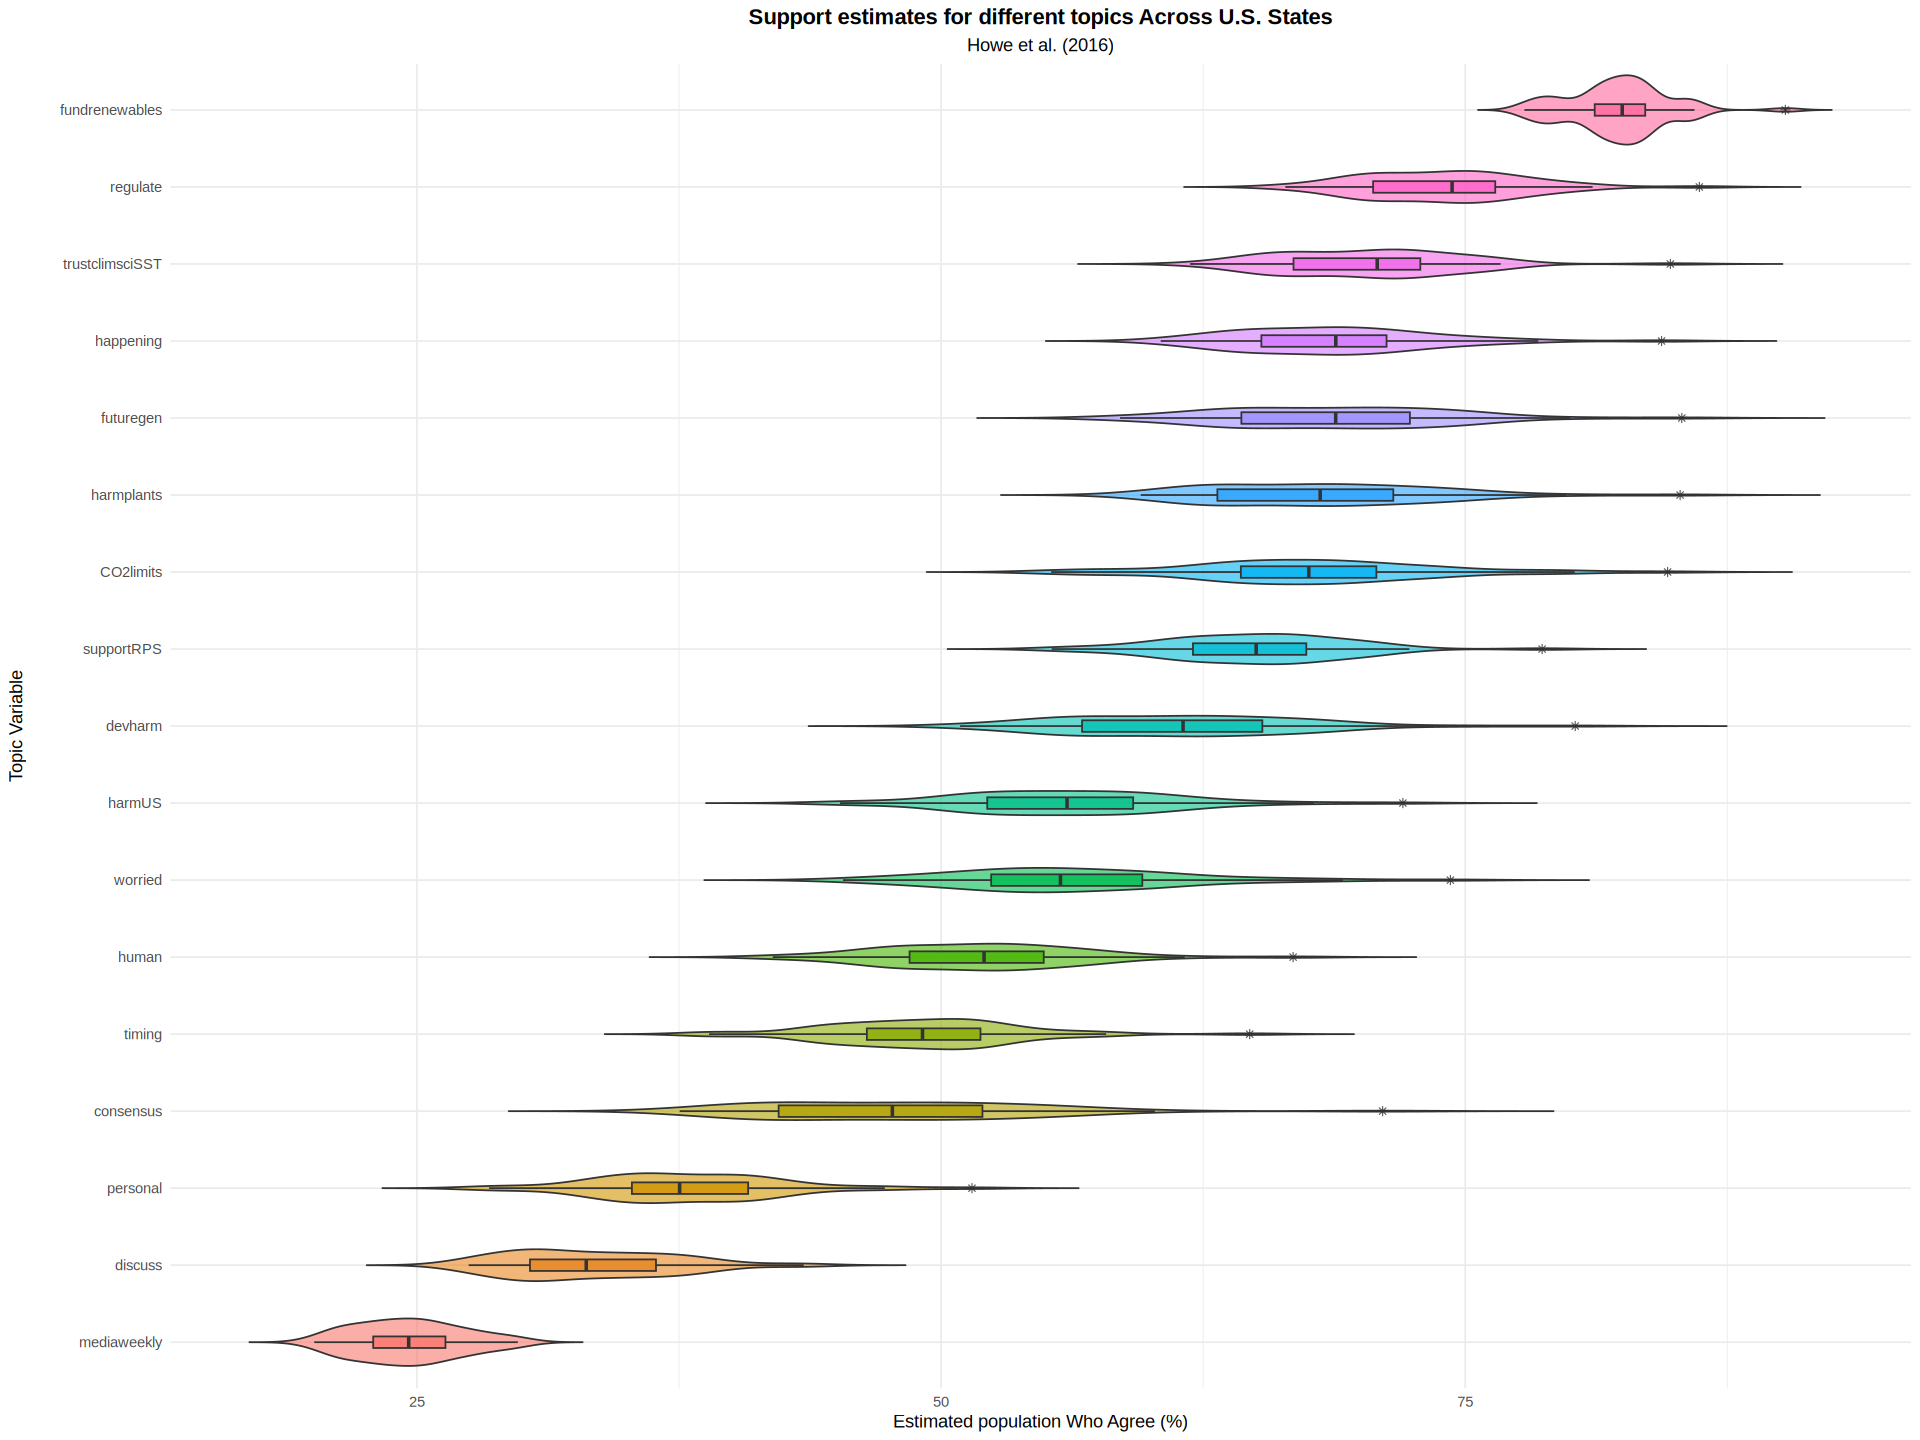

In [34]:
library(dplyr)
library(tidyr)
library(ggplot2)

# filter for only state rows
states <- climate %>%
  filter(GeoType == "State")

# 51 states
nrow(states)

# one row per state per variable
states_long <- states %>%
  select(-GeoType, -GEOID, -TotalPop, -ends_with("Oppose")) %>%
  pivot_longer(
    cols = -GeoName,
    names_to = "Variable",
    values_to = "Percent"
  ) %>%
  mutate(Variable = reorder(Variable, Percent, FUN = median))

# plot size
options(repr.plot.width = 16, repr.plot.height = 12)

# violin boxplot plotting function
ggplot(states_long, aes(x = Variable, y = Percent, fill = Variable)) +
  geom_violin(
    alpha = 0.6,
    trim = FALSE
  ) +
  geom_boxplot(
    width = 0.15,
    alpha = 0.8,
    outlier.shape = 8
  ) +
  coord_flip() +
  labs(
    title = "Support estimates for different topics Across U.S. States",
    subtitle = "Howe et al. (2016)",
    x = "Topic Variable",
    y = "Estimated population Who Agree (%)"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    plot.subtitle = element_text(hjust = 0.5),
    plot.caption = element_text(hjust = 0.5, size = 10),
    legend.position = "none"
  )

In [35]:
# summary statistics of all support variables across 51 states
# basically summary statistics of what is shown in the above violin boxplot
states_long %>%
  group_by(Variable) %>%
  summarise(
    mean   = mean(Percent),
    sd     = sd(Percent),
    median = median(Percent),
    Q1     = quantile(Percent, 0.25),
    Q3     = quantile(Percent, 0.75),
    IQR    = IQR(Percent),
    min    = min(Percent),
    max    = max(Percent)
  ) %>%
  arrange(desc(median))

Variable,mean,sd,median,Q1,Q3,IQR,min,max
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
fundrenewables,82.30625,2.396609,82.488,81.1765,83.5865,2.4100,77.823,90.270
regulate,73.94051,3.926158,74.374,70.6080,76.4330,5.8250,66.421,86.167
trustclimsciSST,70.36949,4.345906,70.803,66.8110,72.8580,6.0470,61.881,84.786
happening,68.71284,4.752808,68.827,65.2775,71.2475,5.9700,60.476,84.364
futuregen,68.70975,5.540837,68.822,64.3235,72.3610,8.0375,58.537,85.330
harmplants,68.12963,5.422478,68.082,63.1785,71.5690,8.3905,59.526,85.250
CO2limits,67.66314,6.006780,67.538,64.2980,70.7625,6.4645,55.252,84.652
supportRPS,65.01375,4.358179,65.029,62.0145,67.4200,5.4055,55.274,78.667
devharm,61.41222,5.873408,61.542,56.7255,65.3240,8.5985,50.906,80.246


##Linear Regression Model

### Variables

| Role | Symbol | Variable | Description | Unit |
|---|---|---|---|---|
| Outcome | $y$ | `discuss` | Estimated percentage who discuss global warming occassionally or often with friends and family | % |
| Predictor | $W$ | `worried` | Estimated percentage who are somewhat/very worried about global warming | % |
| Predictor | $L$ | $\log_{10}(\text{TotalPop})$ | total population of a county in the log space | scaler value in log-space |
| Predictor (Interaction term) | $W.L$ | product of centered $W$ and $L$ | does the effect of $W$ change with $L$? | scalar unit |

### Assumptions and Justification (for above terms)

- **$W \rightarrow y$ :** I can assume that people will only discuss a topic when it concerns/worries them in some way. I assume $\beta_1 > 0$.
- **$L \rightarrow y$ :** population size of a county affects how the community interacts including social, economic, and political issues.
- **$W \times L \rightarrow y$ :** The same level of `worried` may produce different amounts of `discuss` in different places. If neighbours do not have similar concerns then the scope of discussion is limited (Geiger & Swim, 2016). This effect may be different as we scale across different population sizes in counties.

### Model

First, we center both W, L predictors by subtracting each mean else the product term strongly correlates with W and L:

$$W_c = W - \bar{W}, \qquad L_c = L - \bar{L}$$

Then model fit:

$$\text{discuss}_i = \beta_0 + \beta_1 W_{c,i} + \beta_2 L_{c,i} + \beta_3 \left( W_{c,i} \times L_{c,i} \right), \qquad i = 1, \dots, 3142$$

where:

| Coefficient | Interpretation |
|---|---|
| $\beta_0$ | bias term for `discuss` for a county with average `worried` and average population size |
| $\beta_1$ | change in `discuss` per 1-point increase in `worried`, at average county size |
| $\beta_2$ | change in `discuss` per tenfold increase in $\log_{10}(TotalPop)$, at average worry |
| $\beta_3$ | change in the slope of `worried` per tenfold increase in population |

The slope of `worried` at any county size is:

$$\frac{\partial\, \text{discuss}}{\partial W} = \beta_1 + \beta_3 \left( L - \bar{L} \right)$$

### Steps

**dataprep**
- county ($n = 3142$)
- $L = \log_{10}(\text{TotalPop})$
- calculation of $W_c$ and $L_c$

**data exploration**
- scatterplot of `discuss` vs. `worried`
- pairwise correlations for y, W and L

**model fitting (one term at a time)**
- Model A: $y \sim W_c$
- Model B: $y \sim W_c + L_c$
- Model C: $y \sim W_c + L_c + W_c \times L_c$

**Model Comparison**
- I will use $F$-test to compare all models: ANOVA test / F-test checks if each added term explains significantly more variance.
- calculating $R^2$, adjusted-$R^2$, and $\Delta R^2$

**Model predictions at different values of L**: For all three models, I will also calculate $\beta_1 + \beta_3 (L - \bar{L})$ at three county sizes to see how the `worried` slope changes from small to large counties.:

| County type | Adults | $L$ |
|---|---|---|
| Small rural | 10,000 | 4 |
| Medium | 100,000 | 5 |
| Large urban | 1,000,000 | 6 |

**Results**: $β$, 95% CI, p-value for all models

### Limitations

* **same source bias:** `discuss` and `worried` are both % estimates from the same source (Howe et al., 2016) which is the population so their correlation is inflated.
* **Direction:** discussion can increase worry as easily as worry increases discussion which is a natural assumption. Hence, the results show only correlation and not causation.
* **proxy/confounding variables:** 'total population' of a county also correlates with the local community level of education, age, and political alignment which affect `discuss` and `worried`.
* **error**: I did not include an error term in the linear regression model which we normally should. Including an error term would also mean the model has to estimate error in the statistical estimations and also report them.

### Assumptions of Linear Regression
* Linear relationship: The dependent and independent variables are linearly related.
* No multicollinearity: Independent variables should not be highly correlated.
* Homoscedasticity: The error term should remain constant across all levels of the independent variables.
* Normal distribution of error terms: Error terms should follow a normal distribution.
* No autocorrelation: The error terms should not show patterns.

In [36]:
#Data preparation
# filter for data from counties only for model fitting
counties <- climate %>%
  filter(GeoType == "County") %>%
  mutate(
    y   = discuss,
    W   = worried,
    L   = log10(TotalPop),
    W_c = W - mean(W),
    L_c = L - mean(L)
  )

# 3142
nrow(counties)

[1] 3142

###Exploratory Data Analysis

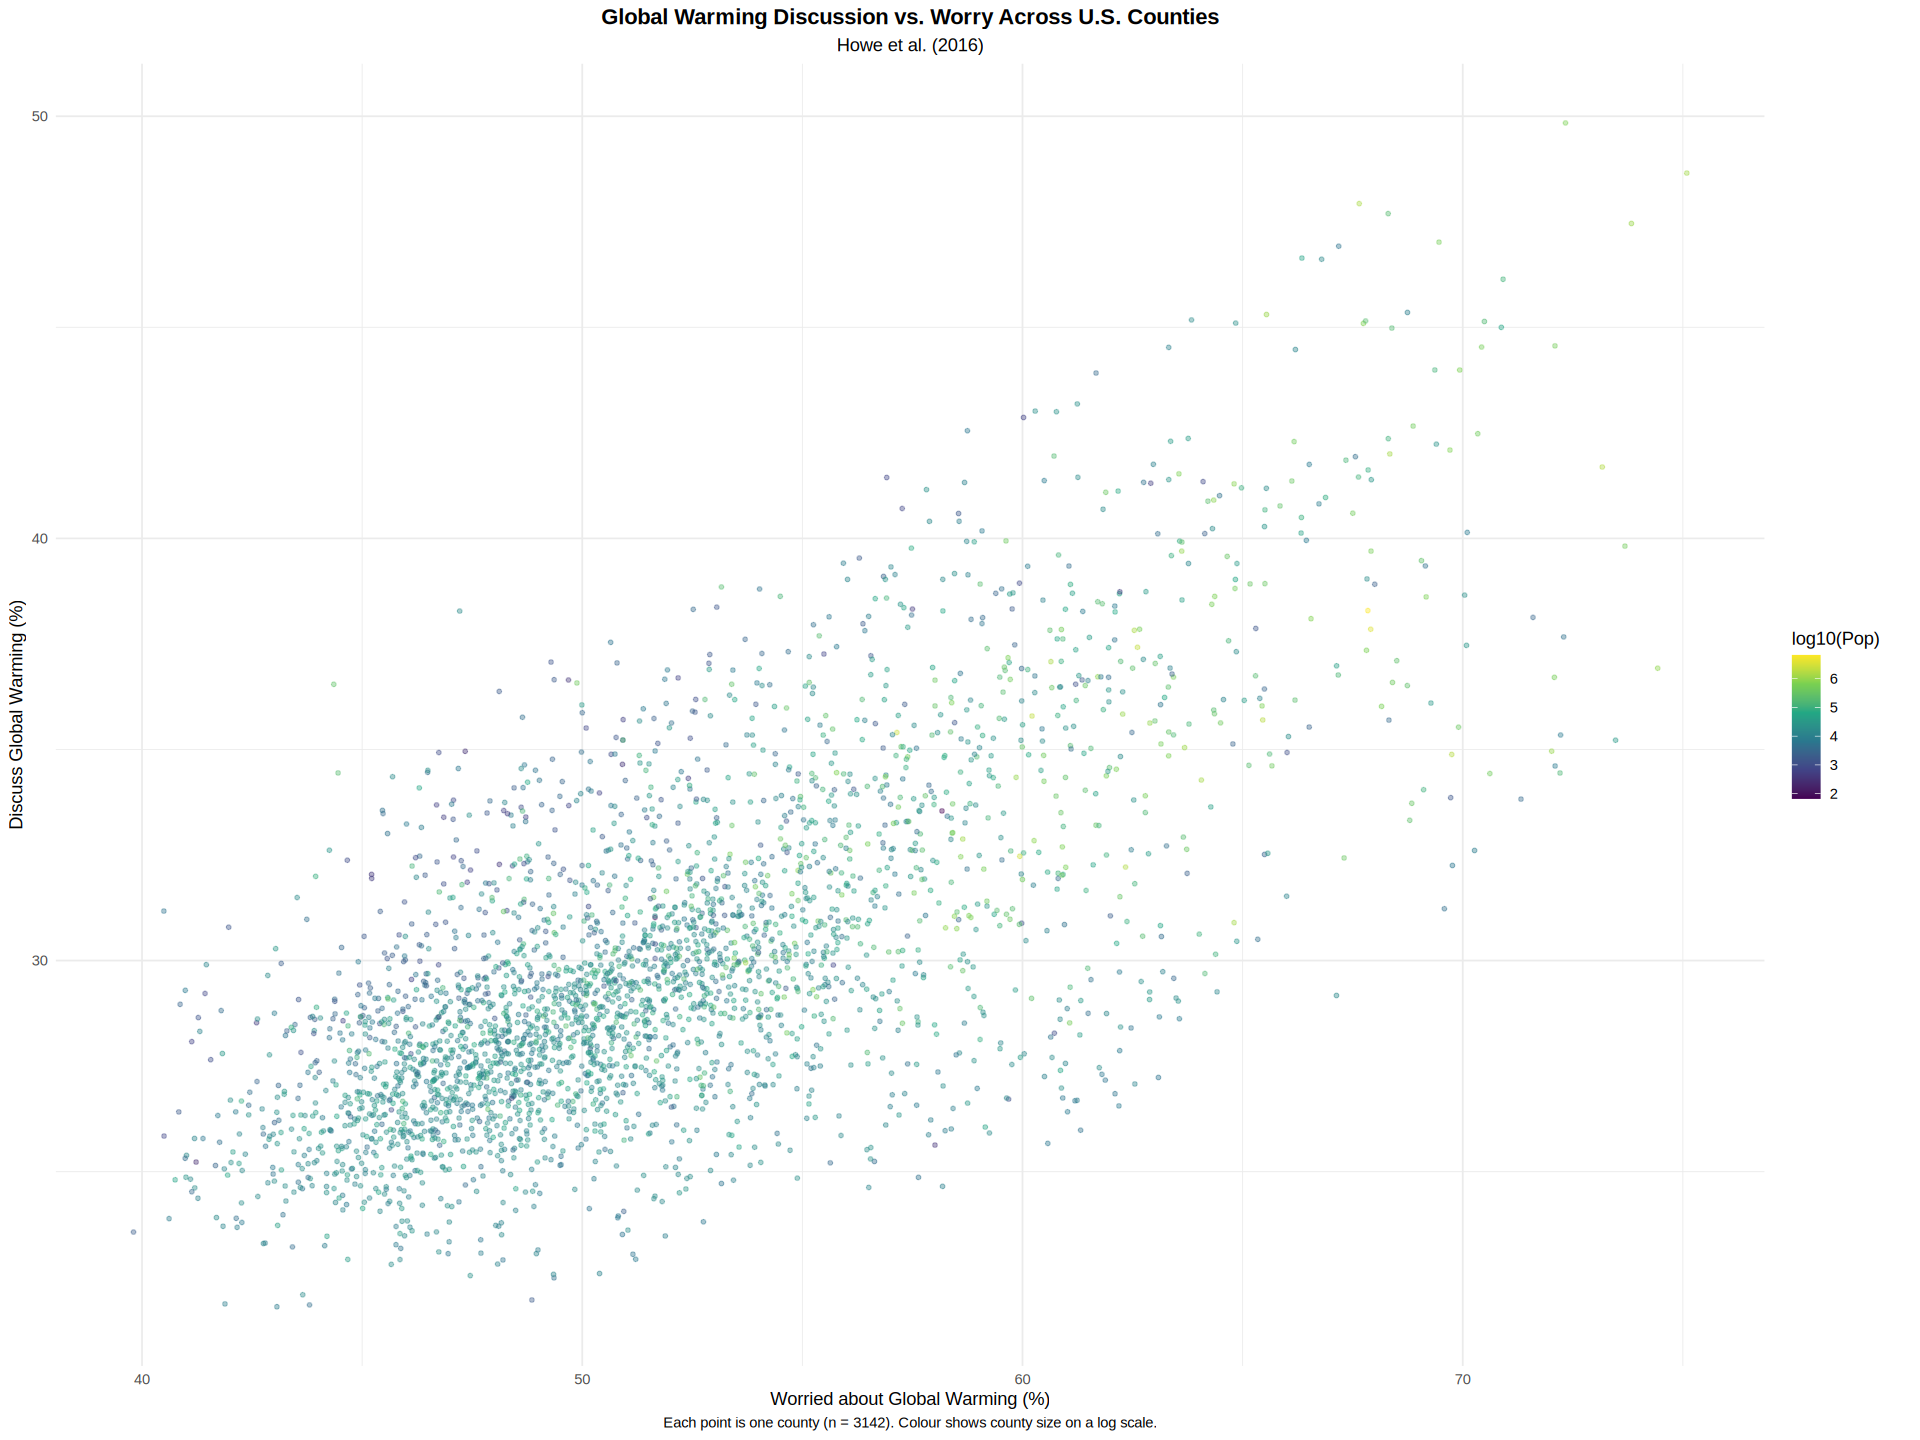

In [37]:
#exploratory data analysis
# scatter plot of discuss and worried across all counties
ggplot(counties, aes(x = W, y = y, colour = L)) +
  geom_point(alpha = 0.4, size = 1) +
  scale_colour_viridis_c(name = "log10(Pop)") +
  labs(
    title = "Global Warming Discussion vs. Worry Across U.S. Counties",
    subtitle = "Howe et al. (2016)",
    x = "Worried about Global Warming (%)",
    y = "Discuss Global Warming (%)",
    caption = "Each point is one county (n = 3142). Colour shows county size on a log scale."
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    plot.subtitle = element_text(hjust = 0.5),
    plot.caption = element_text(hjust = 0.5)
  )

###Pairwise Correlation Matrix

In [38]:
# Pairwise correlation of discuss, worried and population size
cor(counties[, c("y", "W", "L")])

# cor.test() is a statistical hypothesis test
# to assess the association (correlation) between
# two numeric variables: y, W and L (so 3 tests) using counties dataset

# r(W, y)
#cor.test(counties$W, counties$y)

# r(L, y)
#cor.test(counties$L, counties$y)

# r(W, L)
#cor.test(counties$W, counties$L)

,y,W,L
y,1.0000000,0.6976437,0.1799115
W,0.6976437,1.0000000,0.3308078
L,0.1799115,0.3308078,1.0000000


###Model Fitting

In [39]:
# Model fitting
# one term at a time to check
# for change in model performance improvement with every new variable
modelA <- lm(y ~ W_c,             data = counties)
modelB <- lm(y ~ W_c + L_c,       data = counties)
modelC <- lm(y ~ W_c + L_c + W_c:L_c, data = counties)

# summary of the model statistics
summary(modelA)


Call:
lm(formula = y ~ W_c, data = counties)

Residuals:
    Min      1Q  Median      3Q     Max 
-8.5450 -1.6481 -0.2211  1.5036 10.4766 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 30.096595   0.052150  577.12   <2e-16 ***
W_c          0.476790   0.008738   54.56   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.923 on 3140 degrees of freedom
Multiple R-squared:  0.4867,	Adjusted R-squared:  0.4865 
F-statistic:  2977 on 1 and 3140 DF,  p-value: < 2.2e-16


In [40]:
summary(modelB)


Call:
lm(formula = y ~ W_c + L_c, data = counties)

Residuals:
    Min      1Q  Median      3Q     Max 
-8.8845 -1.6195 -0.1604  1.4920 10.8682 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 30.096595   0.052010 578.666  < 2e-16 ***
W_c          0.489705   0.009235  53.030  < 2e-16 ***
L_c         -0.368892   0.087254  -4.228 2.43e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.915 on 3139 degrees of freedom
Multiple R-squared:  0.4896,	Adjusted R-squared:  0.4893 
F-statistic:  1506 on 2 and 3139 DF,  p-value: < 2.2e-16


In [41]:
summary(modelC)


Call:
lm(formula = y ~ W_c + L_c + W_c:L_c, data = counties)

Residuals:
    Min      1Q  Median      3Q     Max 
-8.2003 -1.6258 -0.0966  1.4699 12.0010 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 29.948987   0.053089 564.133  < 2e-16 ***
W_c          0.474947   0.009192  51.669  < 2e-16 ***
L_c         -0.654449   0.090111  -7.263 4.76e-13 ***
W_c:L_c      0.118365   0.011404  10.379  < 2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 2.867 on 3138 degrees of freedom
Multiple R-squared:  0.5066,	Adjusted R-squared:  0.5061 
F-statistic:  1074 on 3 and 3138 DF,  p-value: < 2.2e-16


###Model Comparison

In [42]:
# Model comparison
# F-test: do newly added terms explain more of the variance
# anova() method is used for F-test in R
anova(modelA, modelB, modelC)

# R^2, adjusted R^2, and delta R^2
R2    <- c(summary(modelA)$r.squared,
           summary(modelB)$r.squared,
           summary(modelC)$r.squared)
adjR2 <- c(summary(modelA)$adj.r.squared,
           summary(modelB)$adj.r.squared,
           summary(modelC)$adj.r.squared)

data.frame(
  Model   = c("A", "B", "C"),
  R2      = round(R2, 4),
  adjR2   = round(adjR2, 4),
  deltaR2 = round(c(NA, diff(R2)), 4)
)

,Res.Df,RSS,Df,Sum of Sq,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,3140,26831.31,NA,NA,NA,NA
2,3139,26679.39,1,151.9183,18.48185,1.767521e-05
3,3138,25793.94,1,885.4542,107.72126,7.767865e-25


Model,R2,adjR2,deltaR2
<chr>,<dbl>,<dbl>,<dbl>
A,0.4867,0.4865,NA
B,0.4896,0.4893,0.0029
C,0.5066,0.5061,0.0169


###Model predictions at different values of L

County,People,L,A,B,C
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Small rural,1e+04,4,0.4767902,0.4897055,0.4404194
Medium,1e+05,5,0.4767902,0.4897055,0.5587848
Large urban,1e+06,6,0.4767902,0.4897055,0.6771503


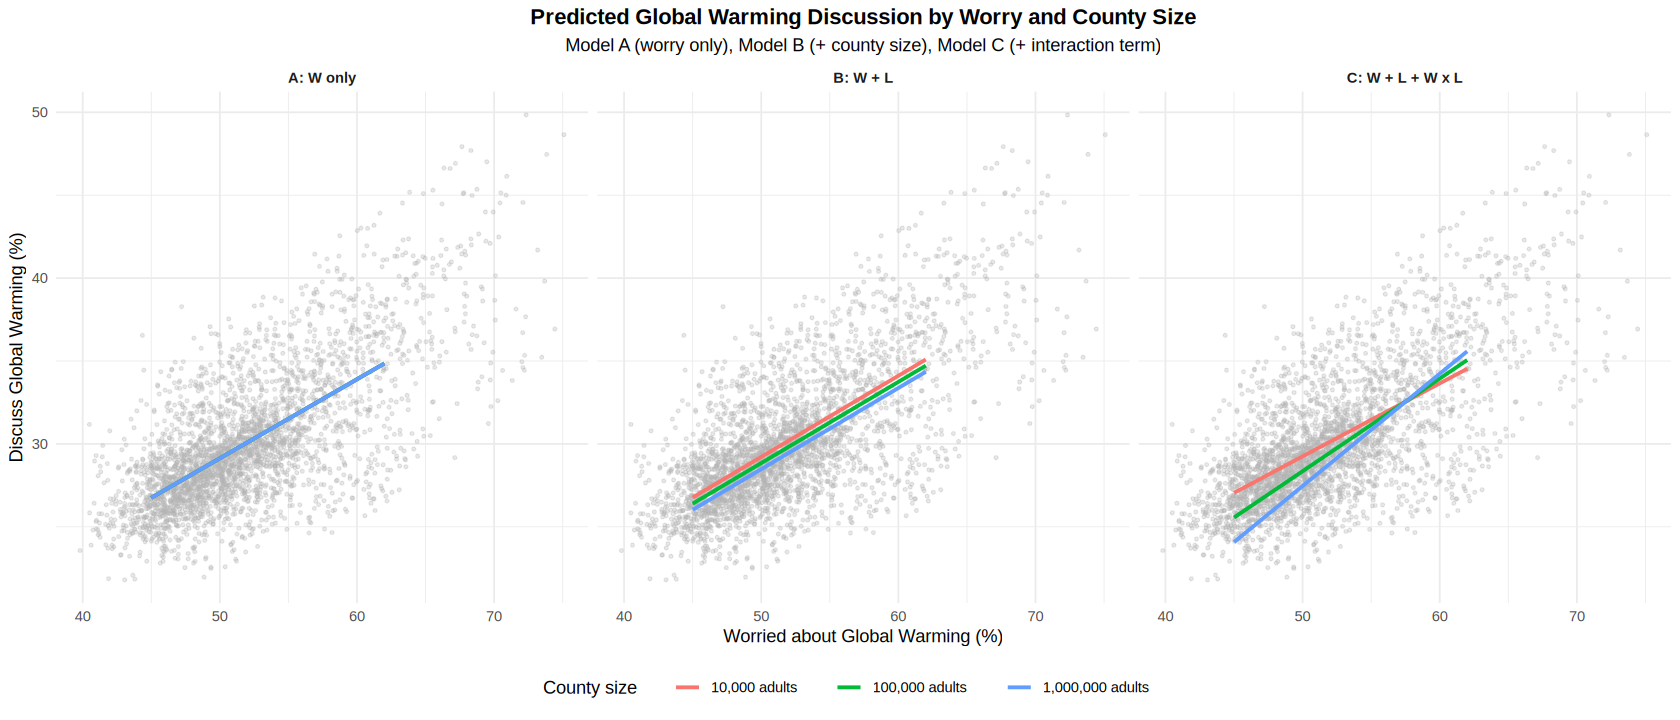

In [43]:
# Claude helped improve this code with suggestions on expand.grid()

# model prediction with different population sizes for all three models

L_bar <- mean(counties$L)
W_bar <- mean(counties$W)

pred_grid <- expand.grid(
  W = seq(45, 62, length.out = 100),
  L = c(4, 5, 6)
)
pred_grid$W_c  <- pred_grid$W - W_bar
pred_grid$L_c  <- pred_grid$L - L_bar
pred_grid$Size <- factor(pred_grid$L,
                         labels = c("10,000 adults", "100,000 adults", "1,000,000 adults"))

# predictions from all three models
pred_all <- bind_rows(
  mutate(pred_grid, Model = "A: W only",           pred = predict(modelA, newdata = pred_grid)),
  mutate(pred_grid, Model = "B: W + L",            pred = predict(modelB, newdata = pred_grid)),
  mutate(pred_grid, Model = "C: W + L + W x L",    pred = predict(modelC, newdata = pred_grid))
)

# slopes of 'worried' for all three models
slopes_all <- data.frame(
  County = c("Small rural", "Medium", "Large urban"),
  People = c(10000, 100000, 1000000),
  L      = c(4, 5, 6)
)
slopes_all$A <- as.numeric(coef(modelA)["W_c"])
slopes_all$B <- as.numeric(coef(modelB)["W_c"])
slopes_all$C <- as.numeric(coef(modelC)["W_c"] +
                           coef(modelC)["W_c:L_c"] * (slopes_all$L - L_bar))
slopes_all

# plot size
options(repr.plot.width = 14, repr.plot.height = 6)

# plotting function
ggplot() +
  geom_point(data = counties, aes(x = W, y = y),
             colour = "grey70", alpha = 0.3, size = 0.8) +
  geom_line(data = pred_all, aes(x = W, y = pred, colour = Size),
            linewidth = 1.1) +
  facet_wrap(~ Model) +
  labs(
    title = "Predicted Global Warming Discussion by Worry and County Size",
    subtitle = "Model A (worry only), Model B (+ county size), Model C (+ interaction term)",
    x = "Worried about Global Warming (%)",
    y = "Discuss Global Warming (%)",
    colour = "County size"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    plot.subtitle = element_text(hjust = 0.5),
    plot.caption = element_text(hjust = 0.5),
    legend.position = "bottom",
    strip.text = element_text(face = "bold")
  )

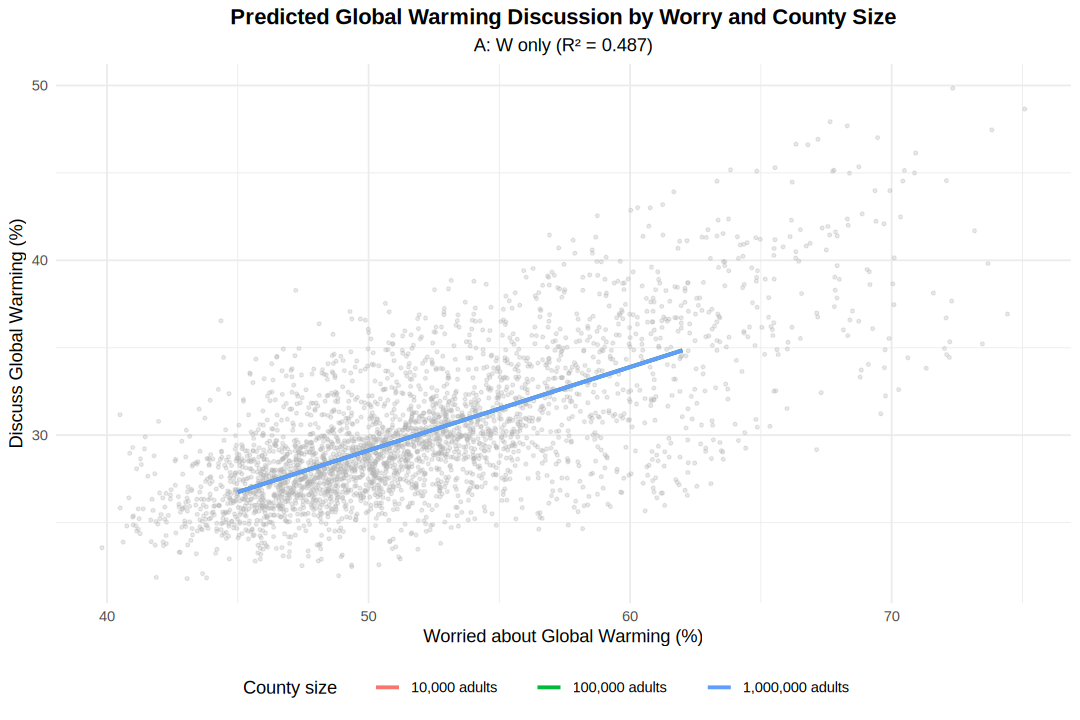

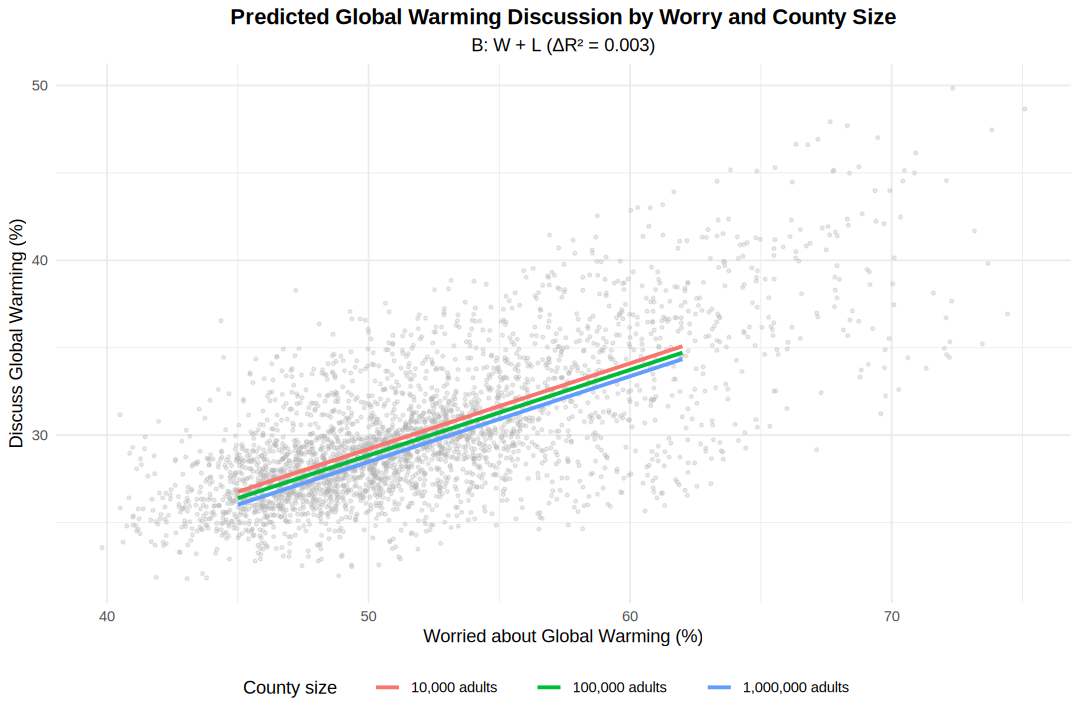

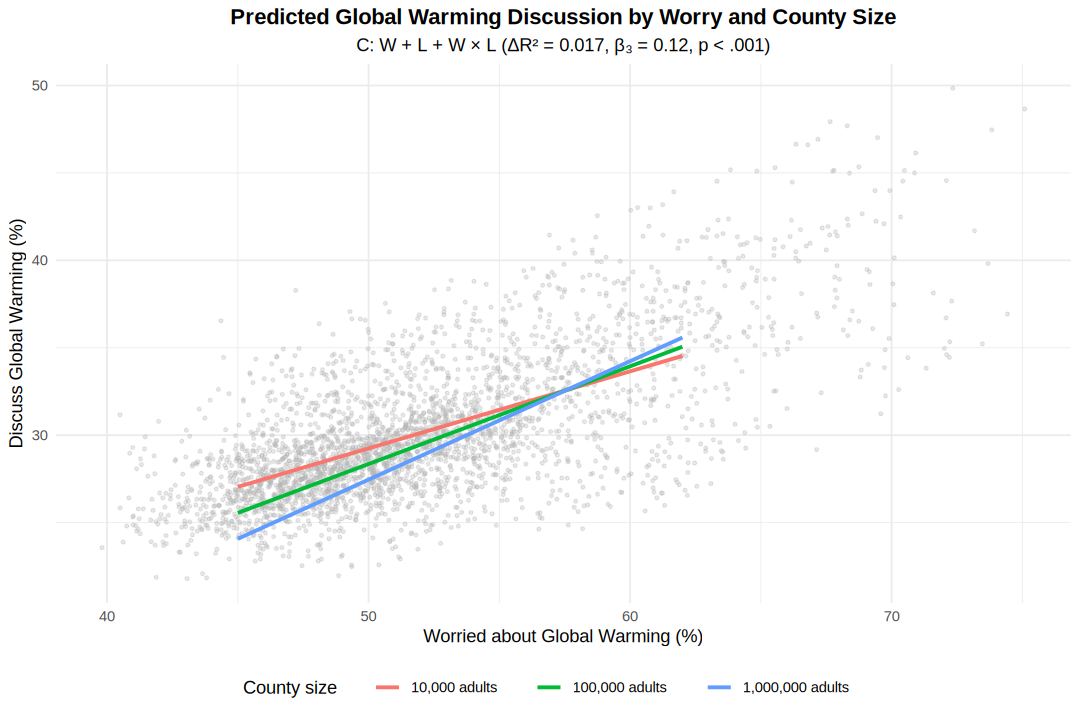

In [48]:
pred_all <- bind_rows(
  mutate(pred_grid, id = "A", Model = "A: W only (R² = 0.487)",
         pred = predict(modelA, newdata = pred_grid)),
  mutate(pred_grid, id = "B", Model = "B: W + L (ΔR² = 0.003)",
         pred = predict(modelB, newdata = pred_grid)),
  mutate(pred_grid, id = "C", Model = "C: W + L + W × L (ΔR² = 0.017, β₃ = 0.12, p < .001)",
         pred = predict(modelC, newdata = pred_grid))
)

#plot one model at a time for ease of viewing than plotting all three models
plot_model <- function(model_id) {
  one <- filter(pred_all, id == model_id)

  ggplot() +
    geom_point(data = counties, aes(x = W, y = y),
               colour = "grey70", alpha = 0.3, size = 0.8) +
    geom_line(data = one, aes(x = W, y = pred, colour = Size),
              linewidth = 1.1) +
    labs(
      title = "Predicted Global Warming Discussion by Worry and County Size",
      subtitle = unique(one$Model),
      x = "Worried about Global Warming (%)",
      y = "Discuss Global Warming (%)",
      colour = "County size"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(hjust = 0.5, face = "bold"),
      plot.subtitle = element_text(hjust = 0.5),
      plot.caption = element_text(hjust = 0.5),
      legend.position = "bottom"
    )
}

options(repr.plot.width = 9, repr.plot.height = 6)

plot_model("A")
plot_model("B")
plot_model("C")

###Results

In [45]:
#Results: beta, 95% CI, p-value for Model A
results <- data.frame(
  beta  = coef(modelA),
  CI_lo = confint(modelA)[, 1],
  CI_hi = confint(modelA)[, 2],
  p     = summary(modelA)$coefficients[, 4]
)
results

,beta,CI_lo,CI_hi,p
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),30.0965955,29.9943443,30.198847,0
W_c,0.4767902,0.4596575,0.493923,0


In [46]:
#Results: beta, 95% CI, p-value for Model B
results <- data.frame(
  beta  = coef(modelB),
  CI_lo = confint(modelB)[, 1],
  CI_hi = confint(modelB)[, 2],
  p     = summary(modelB)$coefficients[, 4]
)
results


,beta,CI_lo,CI_hi,p
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),30.0965955,29.9946179,30.1985731,0.000000e+00
W_c,0.4897055,0.4715992,0.5078118,0.000000e+00
L_c,-0.3688923,-0.5399736,-0.1978111,2.427386e-05


In [47]:
#Results: beta, 95% CI, p-value for Model C
results <- data.frame(
  beta  = coef(modelC),
  CI_lo = confint(modelC)[, 1],
  CI_hi = confint(modelC)[, 2],
  p     = summary(modelC)$coefficients[, 4]
)
results

,beta,CI_lo,CI_hi,p
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),29.9489870,29.84489530,30.0530787,0.000000e+00
W_c,0.4749472,0.45692404,0.4929703,0.000000e+00
L_c,-0.6544489,-0.83113099,-0.4777667,4.763192e-13
W_c:L_c,0.1183654,0.09600452,0.1407264,7.767865e-25
